# 09 — Visualisasi Ruang Fitur (t-SNE & UMAP)

Karena ketiga model memakai *feature extraction* (backbone beku, hanya head yang dilatih), kualitas klasifikasi hampir sepenuhnya ditentukan oleh seberapa terpisah kelas-kelas itu **sudah** berada di ruang fitur ImageNet tiap arsitektur. Head linear tidak bisa memisahkan yang memang tumpang tindih.

Fitur diambil dari lapisan *penultimate* (masukan head): 2048-d untuk ResNet-50 dan InceptionV3, 960-d untuk MobileNetV3.

> **t-SNE dan UMAP adalah alat lihat, bukan alat ukur.** Jarak antar-klaster pada proyeksi 2D tidak bisa dibaca kuantitatif. Untuk angka, pakai *silhouette score* yang dihitung di ruang fitur berdimensi penuh.

## Setup

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: c:\Users\DZXP\Documents\ta-green-bean


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from configs.base_config import (
    ANALYSIS_DIR,
    CLASS_NAMES,
    CROPS_DIR,
    DEVICE,
    FIGURES_DIR,
    MODELS_DIR,
    NUM_CLASSES,
    RANDOM_SEED,
)
from configs.cnn_config import CNN_CONFIG
from src.analysis.feature_visualization import (
    cluster_separation_score,
    compute_tsne,
    compute_umap,
    extract_features,
    load_features,
    plot_projection_comparison,
    save_features,
)
from src.analysis.style import apply_plot_style
from src.utils.seed import set_seed

apply_plot_style()
set_seed(RANDOM_SEED)
MAX_SAMPLES = 2000  # batas agar t-SNE tidak kelamaan

## 1. Muat fitur

`scripts.evaluate` sudah menyimpan fitur ke `results/analysis/*.npz`. Sel di bawah memakainya bila ada; kalau belum, fitur diekstrak ulang dari checkpoint.

In [3]:
features_by_model = {}

for name in CNN_CONFIG:
    path = ANALYSIS_DIR / f'{name}_test_features.npz'
    if path.exists():
        features, labels = load_features(path)
        features_by_model[name] = (features[:MAX_SAMPLES], labels[:MAX_SAMPLES])
        print(f'{name}: dimuat dari {path.name}, shape={features.shape}')
    else:
        print(f'{name}: {path.name} belum ada (lihat sel berikut)')

resnet50: dimuat dari resnet50_test_features.npz, shape=(863, 2048)
mobilenetv3: dimuat dari mobilenetv3_test_features.npz, shape=(863, 960)
inceptionv3: dimuat dari inceptionv3_test_features.npz, shape=(863, 2048)


In [4]:
# Fallback: ekstrak ulang dari checkpoint bila .npz belum ada.
if len(features_by_model) < len(CNN_CONFIG):
    from torch.utils.data import DataLoader

    from src.data.dataset import GreenBeanDataset
    from src.data.transforms import get_transforms
    from src.models.model_factory import get_model
    from src.utils.io import load_checkpoint

    for name in CNN_CONFIG:
        if name in features_by_model:
            continue
        folder = MODELS_DIR / name
        checkpoints = sorted(folder.glob('*.pt')) if folder.is_dir() else []
        if not checkpoints:
            print(f'{name}: checkpoint tidak ada, dilewati')
            continue

        model = get_model(name, num_classes=NUM_CLASSES, pretrained=False)
        load_checkpoint(model, checkpoints[-1], map_location=DEVICE)

        dataset = GreenBeanDataset(CROPS_DIR / 'test', transform=get_transforms(name, 'test'))
        loader = DataLoader(dataset, batch_size=int(CNN_CONFIG[name]['batch_size']), shuffle=False)
        features, labels = extract_features(model, loader, model_name=name, device=DEVICE)
        save_features(features, labels, ANALYSIS_DIR / f'{name}_test_features.npz',
                      paths=[str(p) for p in dataset.paths])
        features_by_model[name] = (features[:MAX_SAMPLES], labels[:MAX_SAMPLES])
        print(f'{name}: diekstrak ulang, shape={features.shape}')

if not features_by_model:
    raise FileNotFoundError('Tidak ada fitur maupun checkpoint. Jalankan notebook 03-05 dulu.')

## 2. Silhouette score — ukuran pemisahan kelas

Dekat `1` = klaster rapat dan terpisah; dekat `0` = tumpang tindih; negatif = sampel rata-rata lebih dekat ke klaster kelas lain.

In [5]:
rows = []
for name, (features, labels) in features_by_model.items():
    rows.append(
        {
            'model': name,
            'n_samples': int(features.shape[0]),
            'feature_dim': int(features.shape[1]),
            'silhouette': round(cluster_separation_score(features, labels), 4),
        }
    )

df_sep = pd.DataFrame(rows).set_index('model').sort_values('silhouette', ascending=False)
df_sep.to_csv(ANALYSIS_DIR / 'feature_separation.csv', encoding='utf-8')
df_sep

,n_samples,feature_dim,silhouette
model,,,
inceptionv3,863,2048,0.0132
mobilenetv3,863,960,0.0126
resnet50,863,2048,-0.0150


## 3. Proyeksi t-SNE, ketiga arsitektur berdampingan

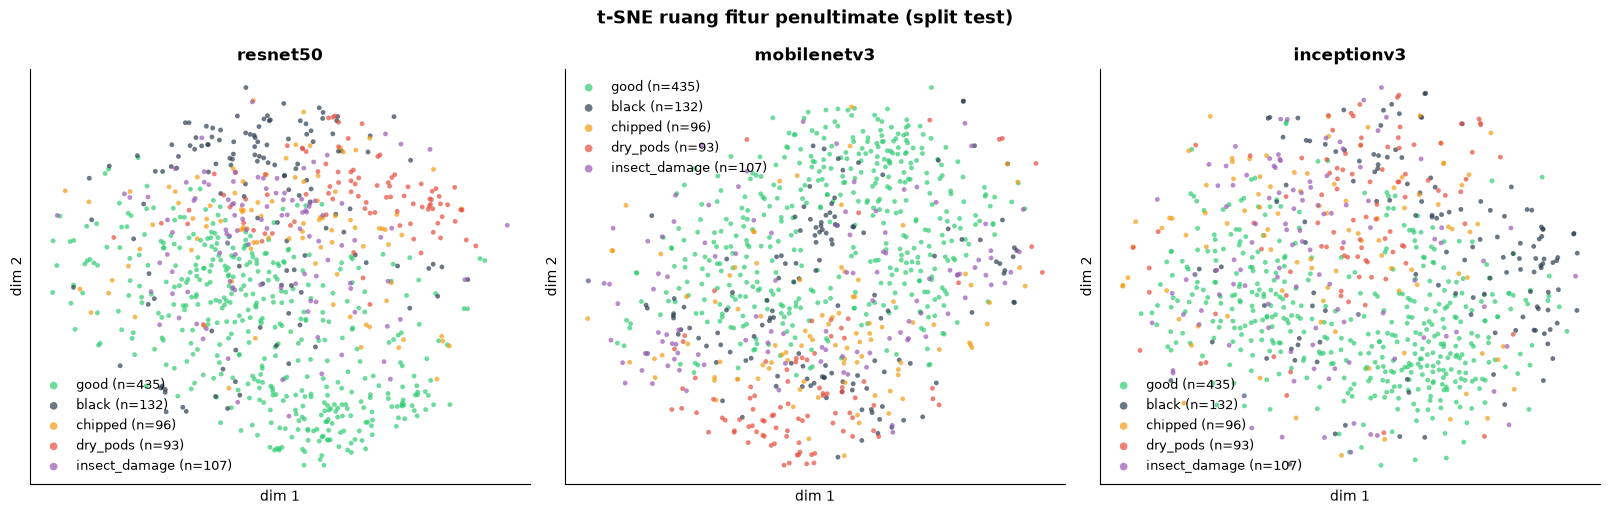

In [6]:
tsne_projections = {
    name: (compute_tsne(features, random_seed=RANDOM_SEED), labels)
    for name, (features, labels) in features_by_model.items()
}

plot_projection_comparison(
    tsne_projections,
    class_names=CLASS_NAMES,
    output_path=FIGURES_DIR / 'tsne_comparison.png',
    suptitle='t-SNE ruang fitur penultimate (split test)',
)
plt.show()

## 4. Proyeksi UMAP

Lebih cepat dari t-SNE dan cenderung mempertahankan struktur global lebih baik. Kalau kesimpulan dari keduanya berbeda, jangan bersandar pada salah satunya.

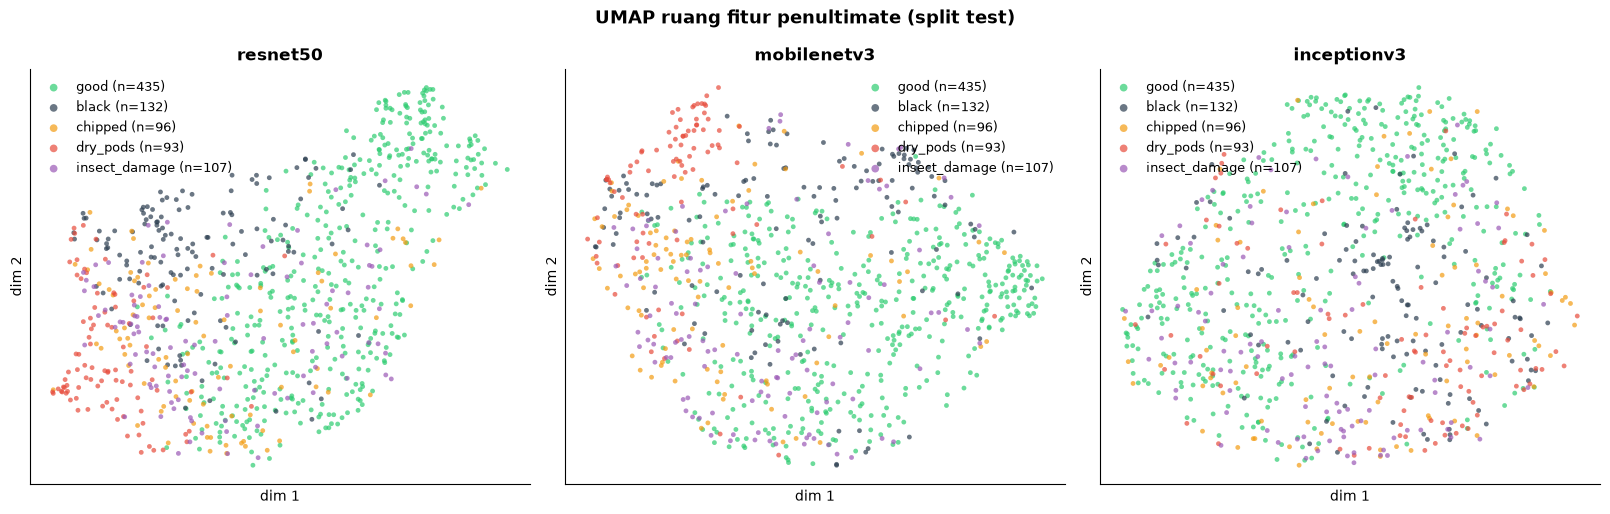

In [7]:
try:
    umap_projections = {
        name: (compute_umap(features, random_seed=RANDOM_SEED), labels)
        for name, (features, labels) in features_by_model.items()
    }
    plot_projection_comparison(
        umap_projections,
        class_names=CLASS_NAMES,
        output_path=FIGURES_DIR / 'umap_comparison.png',
        suptitle='UMAP ruang fitur penultimate (split test)',
    )
    plt.show()
except ImportError as exc:
    print('UMAP dilewati:', exc)

## 5. Kaitkan dengan hasil klasifikasi

Hipotesis yang bisa diuji: arsitektur dengan silhouette tertinggi mestinya juga ber-F1 tertinggi. Kalau tidak, berarti head linear-nya belum memanfaatkan pemisahan yang sudah ada — dan itu temuan yang layak dibahas.

In [8]:
import json

from configs.base_config import METRICS_DIR

rows = []
for name in features_by_model:
    path = METRICS_DIR / f'{name}_test_metrics.json'
    f1 = None
    if path.exists():
        f1 = json.loads(path.read_text(encoding='utf-8')).get('f1')
    rows.append({'model': name, 'silhouette': df_sep.loc[name, 'silhouette'], 'f1': f1})

df_link = pd.DataFrame(rows).set_index('model')
display(df_link)

if df_link['f1'].notna().all() and len(df_link) > 1:
    corr = df_link['silhouette'].corr(df_link['f1'])
    print(f'korelasi silhouette vs F1: {corr:.3f}')
    print('(hanya ' + str(len(df_link)) + ' titik — ini indikasi arah, bukan bukti statistik)')

,silhouette,f1
model,,
resnet50,-0.0150,0.793337
mobilenetv3,0.0126,0.754205
inceptionv3,0.0132,0.742243


korelasi silhouette vs F1: -0.979
(hanya 3 titik — ini indikasi arah, bukan bukti statistik)


## 6. Catatan temuan (isi setelah melihat figurnya)

- Kelas mana yang membentuk klaster paling rapi? Biasanya yang paling khas   secara visual.
- Kelas mana yang tumpang tindih? Cocokkan dengan pola kesalahan di notebook 08   — keduanya mestinya menunjuk pasangan kelas yang sama.
- Apakah `good` terpisah bersih dari keempat kelas cacat? Itu yang paling   menentukan untuk pemakaian quality control.
- Apakah ruang fitur ketiga arsitektur berbeda bentuk secara mencolok?